# Blind retrieval, light curve `lc_e`: a Neptune-size planet on a one-year orbit

This is one of six light curves of a **blind injection-retrieval test**: Nicholas Jannsen simulated PLATO-like
light curves, some (or none) with an exomoon, and sent us the light curves only. We do not know what was injected,
nor which instrumental effects or stellar signals were added. Here we analyse `lc_e` with Pandora, from the raw data
to a Bayes factor and a physical interpretation, in the order one would do it with real data.

We use two routes for the stellar and instrumental trends, and compare them:

- **A, biweight:** detrend the light curve with a robust filter (wotan's biweight, transits masked), then fit the
  transit model with white-noise errors;
- **B, simultaneous GP:** fit the raw flux as transit model + Gaussian process + white noise.

For each route we run the fast detection test `pandora.detect` (seconds) and the full fit `pandora.NestedSampler`
(minutes on a GPU), which gives the evidence of the planet-only and the planet+moon model and the posteriors.

**Contents:** 1. the data and their problems; 2. a model-free look at the transits; 3. priors; 4. cleaning;
5. route A (biweight); 6. route B (GP); 7. the evidence; 8. figures; 9. the physics of the planet+moon solution;
10. further checks (audit, injection-retrieval tests); 11. assessment and learnings.

## 0. Set-up

This notebook needs `pandoramoon` with its optional parts (`pip install "pandoramoon[gpu,plots,search]"` and, for the
GPU, `pip install "numba-cuda[cu13]"`), `pandas` and `pyarrow` (to read the feather files). `blind.py` (in this folder)
holds the helper functions shared by the six notebooks: loading, data checks, the noise model, the two light-curve
preparations and the plots. Every Pandora call is in this notebook.

The full fits run on the GPU (`DEVICE = "gpu"`); `DEVICE = "cpu"` gives the same results, slower. `THREADS` limits the
CPU cores (detection, the planet-only fit, the GP profile). Every fit is stored in `results/`. With `REFIT = False`
(default) the notebook reads the stored fits (`blind.load_fit`: the results Pandora wrote, checked against the current
data and priors; no sampler, no GPU) and runs in a few minutes; it fits only what is not stored yet. With
`REFIT = True` it runs the fits again.

In [1]:
%matplotlib inline
import time as timer
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = [12, 4]

import pandoramoon as pandora
from pandoramoon.gp import GP
import blind

NAME = "e"                # light curve lc_e.ftr
DEVICE = "gpu"            # "cpu" works too (slower)
import os
THREADS = int(os.environ.get("BLIND_THREADS", 5))     # CPU threads (detect, planet-only fits, GP profile)
# REFIT = False: read the stored fits from results/ (no sampler, no GPU); fit only what is not stored yet.
# REFIT = True: run the full fits again (resume="resume" reuses Pandora's stored runs where the data are unchanged)
REFIT = bool(int(os.environ.get("BLIND_REFIT", "0")))
RESULTS = f"results/lc_{NAME}"
from pandoramoon.version import PANDORA_VERSIONING
print("pandoramoon", PANDORA_VERSIONING)

pandoramoon 2.1


## 1. The data, and what is wrong with them

A blind test: we were given the light curve only. The files hold time [s] and flux normalised to 1. Before any fit
we look for the problems a real (or a realistically simulated) light curve has: gaps, jumps between segments, ramps
after gaps, outliers and flares, and a noise level that changes with time. `blind.data_checks` prints a table per
continuous segment; `blind.plot_checks` shows the light curve, the noise level over time, and the flux in the first
and last three days of every segment.

104044 points, cadence 600.004 s, span 729.48 d, 8 segments
segment      start      end       N   mean [ppm]  sigma [ppm/cadence]  slope [ppm/d]
   0       0.00     90.31   13005       -0.7         43.3            -0.023
   1      91.31    181.62   13006       +1.1         44.8            -0.024
   2     182.62    272.93   13005       -0.3         42.4            -0.032
   3     273.93    364.24   13006       +0.9         48.5            -0.003
   4     365.24    455.56   13006       -1.2         44.2            -0.005
   5     456.56    546.86   13005       +1.7         43.9            +0.009
   6     547.86    638.17   13006       -0.5         45.8            -0.012
   7     639.17    729.48   13005       +1.7         46.2            -0.010
jumps across the gaps (12 h after minus 12 h before) [ppm]: +32±8, +31±7, +53±7, +35±9, +50±7, +39±8, +42±9
first 1 d of each segment vs its middle: mean +17.1 ppm (each: +16, +13, +24, +20, +18, +20, +13, +13)
last  1 d of each segment vs its mid

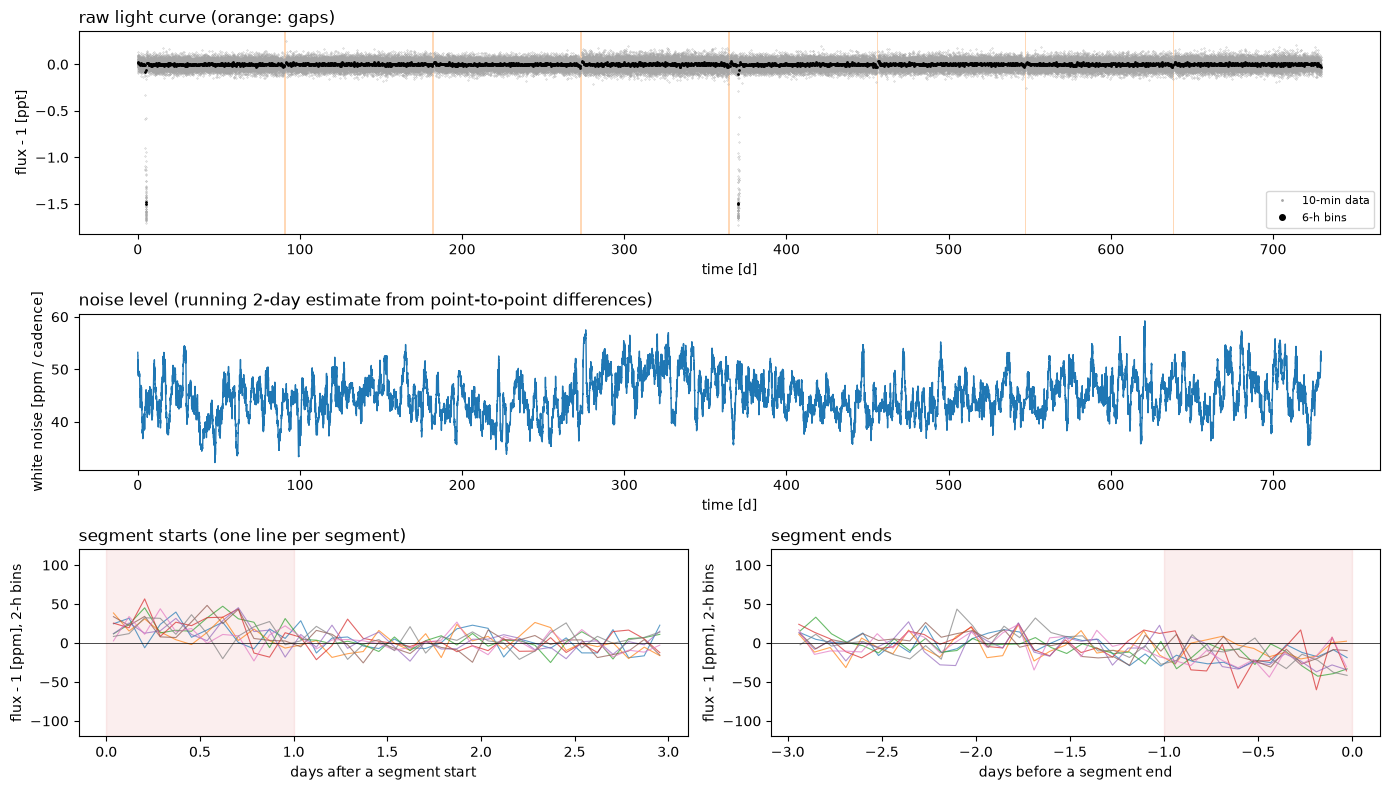

In [2]:
t, f = blind.load(NAME)
checks = blind.data_checks(t, f)
blind.plot_checks(t, f, checks)
plt.show()

**What the checks show.** The common instrument signature of the six light curves:

- 10-min cadence, 8 segments with 1-day gaps;
- segment means within ±2 ppm;
- ramps at the segment edges (+17 / −18 ppm) and jumps of +31 to +53 ppm across the gaps.

The noise is 42–49 ppm per point, nearly constant between segments. Neighbouring points are weakly correlated
(+0.03), the tails slightly heavy (+0.14), with one point beyond 5σ on each side. No flares, spots or stellar
variability.

## 2. A first look at the transits (no model)

We find the transits without a model: runs of points more than 5σ below 1, their mid-times (half-depth crossings),
the period and epoch of a linear ephemeris, the depth and the total duration T14 (from the stack of all transits).
These numbers only centre the priors and set the windows; the fits determine them properly.

In [3]:
ft = blind.find_transits(t, f, checks["sigma"])
T14 = blind.transit_duration(t, f, ft, checks["sigma"])
P, T0 = ft["P"], ft["T0"]
print(f"{len(ft['tmid'])} transits at t = {np.round(ft['tmid'], 3)} d")
print(f"P = {P:.5f} d, T0 = {T0:.5f} d, depth = {1e6 * ft['depth']:.0f} ppm, T14 = {24 * T14:.2f} h")
oc = 1440 * (ft["tmid"] - (T0 + P * ft["epoch"]))
print("mid-times minus the linear ephemeris [min]:", np.round(oc, 2))
print("half-depth durations [min]:", np.round(1440 * ft["dur_half"], 1))
HALF_LOOK = min(1.0, 0.45 * P)          # half-width of the plots below [d]

2 transits at t = [  5.    370.251] d
P = 365.25041 d, T0 = 5.00035 d, depth = 1651 ppm, T14 = 13.50 h
mid-times minus the linear ephemeris [min]: [-0.  0.]
half-depth durations [min]: [750.9 751.1]


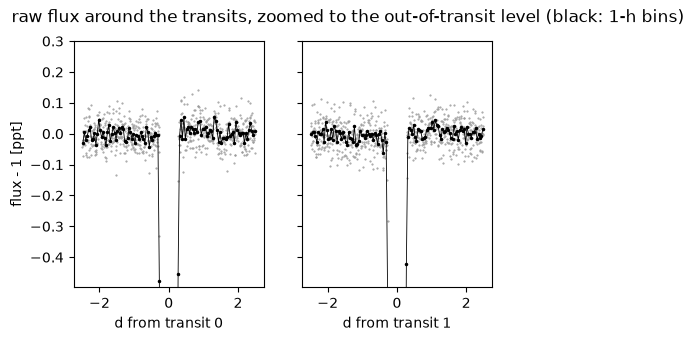

In [4]:
n_show = min(len(ft["tmid"]), 8)
fig, axs = plt.subplots(1, n_show, figsize=(2.2 * n_show + 1, 3.2), sharey=True, squeeze=False)
for k, ax in enumerate(axs[0]):
    tc = ft["tmid"][k]
    m = np.abs(t - tc) < 2.5
    ax.plot(t[m] - tc, 1e3 * (f[m] - 1), ".", ms=1, color="0.6")
    xb, yb, _ = blind.binned(t[m] - tc, f[m], 1 / 24)
    ax.plot(xb, 1e3 * (yb - 1), "k.-", ms=3, lw=0.6)
    ax.set_ylim(-0.12 * 1e3 * ft["depth"] - 0.3, 0.3)
    ax.set_xlabel(f"d from transit {ft['epoch'][k]}")
axs[0, 0].set_ylabel("flux - 1 [ppt]")
plt.suptitle("raw flux around the transits, zoomed to the out-of-transit level (black: 1-h bins)", x=0.01, ha="left")
plt.show()

**Do the transits differ?** Before any model: we align the transits on the linear ephemeris and subtract them from
each other (two transits) or from their median (more transits). A moon shows up as dips that move from transit to
transit, and as changes of the transit's timing and duration (the planet wobbles around the planet-moon
barycentre). Spot crossings would show as short bumps *inside* the transit, instrumental steps as offsets.

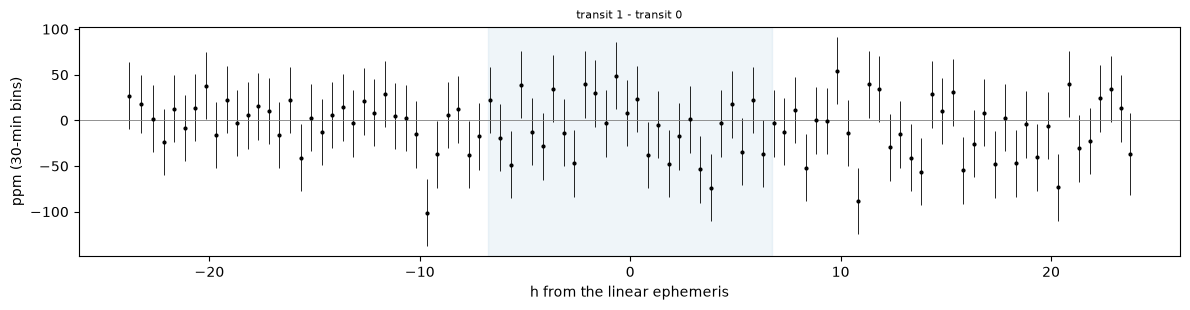

In [5]:
grid = np.arange(-HALF_LOOK, HALF_LOOK, 600 / 86400)
stack = np.array([np.interp(grid, t[np.abs(t - (T0 + P * e)) < HALF_LOOK + 0.1] - (T0 + P * e),
                            f[np.abs(t - (T0 + P * e)) < HALF_LOOK + 0.1]) for e in ft["epoch"]])
ref = stack[0] if len(stack) == 2 else np.median(stack, axis=0)
show_e = range(1, 2) if len(stack) == 2 else range(len(stack))
n_cols = 1 if len(stack) == 2 else min(len(stack), 4)
n_rows = int(np.ceil(len(show_e) / n_cols))
fig, axs = plt.subplots(n_rows, n_cols, figsize=(12 if n_cols == 1 else 3.3 * n_cols, 3.2 * n_rows if n_cols == 1
                        else 2.2 * n_rows), sharex=True, sharey=True, squeeze=False)
sig_med = np.median(checks["sigma"])
for ax, i in zip(axs.flat, show_e):
    xb, db, nb = blind.binned(grid * 24, stack[i] - ref, 0.5)
    ax.errorbar(xb, 1e6 * db, 1e6 * sig_med * np.sqrt(2) / np.sqrt(nb), fmt="o", ms=2, color="k", elinewidth=0.6)
    ax.axhline(0, color="0.5", lw=0.6)
    ax.axvspan(-12 * T14, 12 * T14, color="C0", alpha=0.07)
    ax.set_title(f"transit {ft['epoch'][i]} - " + ("transit 0" if len(stack) == 2 else "median"), fontsize=8)
for ax in axs[-1]:
    ax.set_xlabel("h from the linear ephemeris")
for ax in axs[:, 0]:
    ax.set_ylabel("ppm (30-min bins)")
for ax in axs.flat[len(show_e):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Two transits, one year apart** (days 5.000 and 370.251, P = 365.2504 d), 1 650 ppm deep and 13.5 hours long: a
Neptune-size planet (~4 R_earth) on a one-year orbit around a Sun-like star.

**The transits are identical** within the noise: half-depth durations 750.9 and 751.1 min. The difference of the two
transits is flat; its largest excursions (−100 ppm in one 30-min bin at −9.5 h, −90 ppm at +11 h) are single bins,
as expected from noise in ~100 bins.

## 3. Priors, and how far from the planet a moon can be

We use Pandora's `default_priors` (the priors the detection test was calibrated with), centred on the ephemeris
above. The moon priors are: radius 0.1–0.7 × the planet's, period up to 0.19 × the planet's period (the prograde
stability limit at ~0.48 Hill radii), mass up to half the planet's, all orientations.

The moon can transit up to `reach` days before or after its planet: its largest orbit (the longest prior period,
the heaviest prior planet) divided by the planet's speed. The fit windows must cover the transit and this reach,
otherwise a moon's dip can fall outside the data.

In [6]:
r_planet = float(np.sqrt(ft["depth"]))      # first guess of R_planet / R_star (limb darkening makes it ~5 % too large)
# a ~4 Earth-radius planet: the default mass prior (0.5-1.5 Jupiter masses) does not fit. We use Neptune's mass
# (17 Earth masses; prior 0.5-1.5 x) as the estimate (the moon's orbit and the Hill sphere depend on it)
M_planet = 17 * blind.M_EARTH
priors = pandora.default_priors(t0_bary=round(T0, 2), per_bary=P, r_planet=r_planet, M_planet=M_planet)

In [7]:
for name, prior in priors.items():
    print(f"  {name:16s} {prior}")
reach = blind.moon_reach(P, priors["per_moon"].hi, priors["M_planet"].hi)
HALF = reach["reach_days"] + T14          # half-width of the fit windows [d]
print(f"largest moon orbit {reach['a_moon_max']:.2f} R_star = {reach['reach_days']:.2f} d of planet motion "
      f"(Hill radius {reach['r_hill']:.1f} R_star = {reach['hill_days']:.2f} d); fit windows: +-{HALF:.2f} d")

  q1               Uniform(lo=0.0, hi=1.0)
  q2               Uniform(lo=0.0, hi=1.0)
  R_star           Uniform(lo=557073600.0, hi=835610400.0)
  per_bary         Uniform(lo=364.51990436469754, hi=365.9809059853978)
  a_bary           LogUniform(lo=85.93392782943407, hi=537.0870489339629)
  r_planet         Uniform(lo=0.020317299642963402, hi=0.060951898928890205)
  b_bary           Uniform(lo=0.0, hi=1.0)
  t0_bary          5.0
  t0_bary_offset   Uniform(lo=-0.05, hi=0.05)
  M_planet         Uniform(lo=5.07637e+25, hi=1.522911e+26)
  r_moon           Uniform(lo=0.00406345992859268, hi=0.02844421950014876)
  per_moon         Uniform(lo=0.0, hi=69.398)
  tau_moon         Uniform(lo=0.0, hi=1.0)
  Omega_moon       Uniform(lo=0.0, hi=180.0)
  i_moon           Uniform(lo=0.0, hi=180.0)
  M_moon           Uniform(lo=0.0, hi=5.07637e+25)
largest moon orbit 3.02 R_star = 0.82 d of planet motion (Hill radius 6.3 R_star = 1.71 d); fit windows: +-1.38 d


**Priors.** A planet of ~4 Earth radii: the default mass prior (0.5–1.5 Jupiter masses) does not fit. We use Neptune's
mass, 17 M_earth (prior 8.5–25.5 M_earth). The planet mass sets the moon's orbit for a given period, so it also sets
how far the moon can go: 0.82 days from the planet (with a Jupiter mass it would be 2.2 days). Fit windows: ±1.38
days. The moon prior allows radii of 0.44–3.1 Earth radii (0.1–0.7 × the first-guess planet radius) and masses up to
8.5 M_earth.

## 4. Noise near the transits, segment edges and outliers

Three decisions, the same for both routes:

- **The noise level near the transits.** The running estimate of section 1 uses differences of neighbouring points.
  A deep transit's ingress and egress are steep steps that make large differences; they raise the running median by
  15–20 % within a day of a deep transit, exactly where the error bars matter. (We found this only after a first
  round of fits: their errors were too large near the transits, so their Bayes factors were too small.) So we
  estimate it again with the transits left out and interpolate across them.

- **Segment edges:** the flux drifts by tens of ppm in the first and last day of each segment (section 1). We leave
  out 1 day at each segment edge (2 % of the data). This affects only transit windows that touch a gap.
- **Outliers and flares:** `GP.fit(..., clip=True)` flags points above 4σ everywhere (flares), below 5σ outside the
  transit windows, and isolated one-cadence dips inside them, against the GP's own prediction. We fit the GP's
  hyperparameters here (section 6 explains them) and use its flags in both routes.

In [8]:
# the white-noise level near the transits: the running estimate of section 1 with the transits left out
in_transit = blind.phase_distance(t, T0, P) < 0.5 * T14 + 0.02
sigma = blind.local_sigma(t, f, mask=in_transit)
near = (blind.phase_distance(t, T0, P) < 0.5 * T14 + T14) & ~in_transit     # within one T14 of the transits
print(f"noise near the transits: {1e6 * np.median(sigma[near]):.1f} ppm per cadence; the estimate with the "
      f"transits included was {100 * (np.median(checks['sigma'][near] / sigma[near]) - 1):+.0f} % higher there")
edges = blind.edge_mask(t, edge=1.0)
t_start = timer.time()
# cache: GP.fit's last digits differ between CPUs; the stored hyperparameters make the data bit-identical on any
# machine, so the stored fits below are reused (resume) instead of refitted
gp, gpw, outliers = blind.prepare_gp(t, f, sigma, T0, P, HALF, bad=edges,
                                     kernel="sho", baseline="offset", gap=0.5, clip=True,
                                     cache=f"{RESULTS}/gp_hyper.npz")
bad = edges | outliers
print(f"GP hyperparameters ({'stored' if timer.time() - t_start < 1 else 'GP.fit'}, {timer.time() - t_start:.0f} s): {gp}")
print(f"left out: {edges.sum()} points at segment edges, {outliers.sum()} outliers / flares at t =",
      np.round(t[outliers], 2))
in_win = blind.phase_distance(t, T0, P) < HALF
print(f"outliers inside the fit windows: {(outliers & in_win).sum()}")

noise near the transits: 44.9 ppm per cadence; the estimate with the transits included was +1 % higher there
GP hyperparameters (stored, 0 s): GP(amp=1.05309e-05, tau=0.00694449, Q=0.707107, err_scale=0.989266, baseline='offset', gap=0.5)
left out: 2304 points at segment edges, 6 outliers / flares at t = [ 19.23  39.34 421.22 440.37 526.56 556.99]
outliers inside the fit windows: 0


**Cleaning.** For this shallow transit the noise estimate barely depends on whether the transits are included (+1 %).
The segment edges cost 2 % of the points, none in a fit window; six single-point outliers lie outside the windows.

## 5. Route A: biweight detrending + white-noise fit

The classical route. `pandora.prepare_lightcurve` detrends with wotan's robust `biweight`: the transits are masked
over 1.0 × T14 and the trend is a robust running mean over a window of 4.0 × T14 (Pandora's defaults, from a study of
300 injected moons in real Kepler data). It returns the data in the fit windows (here ±HALF around each transit).

**Error bars.** `prepare_lightcurve` measures one noise level for the whole light curve. Our noise changes with time
(section 1), and it measures β on only ~100 bins next to the transits, where a single noisy bin can change it by
20 %. We replace its errors with the local white noise σ(t) (section 4) times a red-noise factor β measured on all
detrended data outside the windows after dividing by σ(t) (bins of T14 / 4).

In [9]:
bw = blind.prepare_biweight(t, f, sigma, T0, P, T14, HALF, bad=bad)
print(f"{len(bw['time'])} points in {len(bw['epochs'])} fit windows")
print(f"prepare_lightcurve's own errors: one sigma = {1e6 * bw['sigma']:.1f} ppm, beta = {bw['beta']:.2f} "
      f"(beta from ~100 bins next to the transits)")
print(f"local errors: sigma(t) x beta, beta = {bw['beta_local']:.3f}; errors {1e6 * bw['flux_err'].min():.0f} ... "
      f"{1e6 * bw['flux_err'].max():.0f} ppm")
w_tr = blind.phase_distance(bw["time_all"], T0, P) < HALF
print(f"biweight trend inside the windows: {1e6 * (np.nanmin(bw['trend'][w_tr]) - 1):+.0f} ... "
      f"{1e6 * (np.nanmax(bw['trend'][w_tr]) - 1):+.0f} ppm")
like_bw = pandora.Likelihood(bw["time"], bw["flux"], bw["flux_err"], epoch_distance=P, hill_sphere_threshold=1.0)

794 points in 2 fit windows
prepare_lightcurve's own errors: one sigma = 42.9 ppm, beta = 1.07 (beta from ~100 bins next to the transits)
local errors: sigma(t) x beta, beta = 1.060; errors 41 ... 53 ppm
biweight trend inside the windows: -10 ... +8 ppm


### 5.1 Detection: `pandora.detect`

The fast test: one short nested-sampling run of the planet-only model and a few short runs of the planet+moon model.
It returns Δln Z = ln Z(planet+moon) − ln Z(planet only) (noisy, ±0.5) and the **epoch jackknife**: the moon model's
fit improvement Δχ² per transit. A light curve is a *candidate* if Δln Z > 3 and the moon is still significant without
the transit that carries most of it (Δχ² ≥ 18 in the remaining transits). Seconds of CPU time.

In [10]:
det_bw = pandora.detect(like_bw, priors, verbose=True, threads=THREADS)
print("moon (median, 16 %, 84 %):", {k: tuple(round(x, 4) for x in v) for k, v in det_bw["moon"].items()})
print("jackknife dchi2 per transit:", dict(zip(det_bw["jackknife"]["epochs"],
                                                np.round(det_bw["jackknife"]["dchi2_epochs"], 1))))

Pandora: compiling numerical code (first use after installation or an update can take a few minutes; the result is cached) ...


detect: dlnZ = -4.81 +- 1.04 (threshold 3.0); jackknife: -0.4 without the strongest transit (need >= 18.0); candidate: False
moon (median, 16 %, 84 %): {'per_moon': (52.6889, 43.5622, 61.9345), 'r_moon': (0.0104, 0.0089, 0.0117), 'i_moon': (46.2509, 31.4504, 64.2295), 'M_moon/M_planet': (0.005, 0.0024, 0.0101)}
jackknife dchi2 per transit: {0: np.float64(-0.4), 1: np.float64(7.0)}


### 5.2 The full fit: `pandora.NestedSampler` on the GPU

Both models, with checked evidences (±0.2 in ln Z) and posteriors. The planet-only model is fitted on the CPU
(importance sampling), the planet+moon model on the GPU. 10-min cadences are integrated over 5 sub-exposures
(`supersampling="auto"`). The sampler adds runs, live points and chain length until its own checks pass.

In [11]:
t_start = timer.time()
if REFIT or not blind.fit_stored(f"{RESULTS}/biweight"):
    s_bw = pandora.NestedSampler(like_bw, priors, device=DEVICE, threads=THREADS, log_dir=f"{RESULTS}/biweight",
                                 resume="resume", verbose=False)
    r_bw = s_bw.run(progress=False)
else:
    s_bw, r_bw = blind.load_fit(like_bw, priors, f"{RESULTS}/biweight")     # the stored fit, read back
rec_bw = blind.run_record(f"{RESULTS}/biweight", r_bw)
print(f"wall time of this cell: {(timer.time() - t_start) / 60:.1f} min; the planet+moon fit took "
      f"{rec_bw['wall'] / 60:.1f} min ({rec_bw['ncall'] / 1e9:.1f} G likelihood calls) when it ran ({rec_bw['date']})")
s_bw.print_results()

wall time of this cell: 0.0 min; the planet+moon fit took 2.6 min (1.2 G likelihood calls) when it ran (2026-11-21T11:43:04)
planet + moon: logZ = -350.897 +- 0.044   (checks passed; 97 runs x 500 live, nsteps 64, 1,160,696,316 calls, 157 s)
    q1              : 0.427099 -0.0447 +0.0479   (mean 0.428633, sd 0.0465)
    q2              : 0.364357 -0.0462 +0.0509   (mean 0.36669, sd 0.0493)
    R_star          : 6.98116e+08 -9.45e+07 +9.21e+07   (mean 6.97193e+08, sd 7.92e+07)
    per_bary        : 365.251 -0.0138 +0.0121   (mean 365.25, sd 0.0269)
    a_bary          : 210.701 -7.61 +3.48   (mean 209.161, sd 5.97)
    r_planet        : 0.0365932 -0.00017 +0.000333   (mean 0.0365964, sd 0.000568)
    b_bary          : 0.234615 -0.164 +0.191   (mean 0.256802, sd 0.179)
    t0_bary_offset  : -0.000920883 -0.0166 +0.015   (mean -0.00130779, sd 0.0182)
    M_planet        : 1.10184e+26 -3.62e+25 +2.92e+25   (mean 1.07575e+26, sd 2.81e+25)
    r_moon          : 0.0135518 -0.00793 +0.00981   

## 6. Route B: the raw flux with a simultaneous GP

Instead of detrending first, we fit the raw (normalised) flux as **transit model + Gaussian process + white noise**
(`Likelihood(..., gp=gp)`). The GP is an SHO kernel (Q = 1/√2) whose hyperparameters (amplitude, time scale, a factor
on the white noise) were fitted in section 4 by maximum likelihood on the data *outside* the fit windows. The white
noise is σ(t) × err_scale, so the changing noise level is included. `baseline="offset"` with `gap=0.5` gives each
data segment (here: each transit window) its own constant level, marginalised analytically.

The hyperparameters are held fixed during the fit. A planet-only model with a freer GP could explain part of a moon's
dip as noise, so with fixed hyperparameters a real moon's Bayes factor comes out too high. `gp_profile=True` refits
them for each model after the fit and reports the **conservative** Bayes factor `dlogz_conservative`: we quote that
one. (We call it as `blind.gp_profile_cached(s_gp, r_gp)` after the fit: the same computation, stored so that a
second run of the notebook reads it back instead of repeating the refits.)

In [12]:
print(gp)
print(f"GP amplitude {1e6 * gp.amp:.1f} ppm, time scale {24 * 60 * gp.tau:.1f} min, white-noise factor {gp.err_scale:.3f}")
like_gp = pandora.Likelihood(gpw["time"], gpw["flux"], gpw["flux_err"], epoch_distance=P, hill_sphere_threshold=1.0,
                             gp=gp)
det_gp = pandora.detect(like_gp, priors, verbose=True, threads=THREADS)
print("moon (median, 16 %, 84 %):", {k: tuple(round(x, 4) for x in v) for k, v in det_gp["moon"].items()})
print("jackknife dchi2 per transit:", dict(zip(det_gp["jackknife"]["epochs"],
                                                np.round(det_gp["jackknife"]["dchi2_epochs"], 1))))

GP(amp=1.05309e-05, tau=0.00694449, Q=0.707107, err_scale=0.989266, baseline='offset', gap=0.5)
GP amplitude 10.5 ppm, time scale 10.0 min, white-noise factor 0.989


detect: dlnZ = -0.31 +- 1.07 (threshold 3.0); jackknife: 7.3 without the strongest transit (need >= 18.0); candidate: False
moon (median, 16 %, 84 %): {'per_moon': (23.0174, 19.3174, 28.2625), 'r_moon': (0.0044, 0.0042, 0.0047), 'i_moon': (121.471, 101.4064, 143.8476), 'M_moon/M_planet': (0.0107, 0.0051, 0.0174)}
jackknife dchi2 per transit: {0: np.float64(7.3), 1: np.float64(8.8)}


**The GP**: amplitude 10.5 ppm, time scale 10 min (the lower bound), white-noise factor 0.989: the weak neighbouring-point
correlation, nothing else.

In [13]:
t_start = timer.time()
if REFIT or not blind.fit_stored(f"{RESULTS}/gp"):
    s_gp = pandora.NestedSampler(like_gp, priors, device=DEVICE, threads=THREADS, log_dir=f"{RESULTS}/gp",
                                 resume="resume", verbose=False)
    r_gp = s_gp.run(progress=False)
else:
    s_gp, r_gp = blind.load_fit(like_gp, priors, f"{RESULTS}/gp")     # the stored fit, read back
# the conservative Bayes factor (= NestedSampler(..., gp_profile=True)); stored in gp_profile.json and read back
# when the notebook runs again (gp_profile itself would redo its refits)
blind.gp_profile_cached(s_gp, r_gp)
rec_gp = blind.run_record(f"{RESULTS}/gp", r_gp)
print(f"wall time of this cell: {(timer.time() - t_start) / 60:.1f} min; the planet+moon fit took "
      f"{rec_gp['wall'] / 60:.1f} min ({rec_gp['ncall'] / 1e9:.1f} G likelihood calls) when it ran ({rec_gp['date']})")
s_gp.print_results()

wall time of this cell: 0.0 min; the planet+moon fit took 2.4 min (0.6 G likelihood calls) when it ran (2026-11-21T10:55:22)
planet + moon: logZ = -419.091 +- 0.088   (checks passed; 47 runs x 500 live, nsteps 64, 630,531,784 calls, 145 s)
    q1              : 0.428687 -0.0432 +0.0457   (mean 0.430061, sd 0.045)
    q2              : 0.363638 -0.0459 +0.0511   (mean 0.366128, sd 0.0499)
    R_star          : 7.03733e+08 -9.47e+07 +8.89e+07   (mean 7.01472e+08, sd 7.82e+07)
    per_bary        : 365.251 -0.00947 +0.00329   (mean 365.249, sd 0.0212)
    a_bary          : 211.083 -6.3 +2.8   (mean 209.582, sd 5.31)
    r_planet        : 0.0365585 -0.000169 +0.000303   (mean 0.0365646, sd 0.000495)
    b_bary          : 0.176179 -0.122 +0.162   (mean 0.199918, sd 0.146)
    t0_bary_offset  : -0.00487089 -0.0176 +0.00646   (mean -0.00723728, sd 0.0162)
    M_planet        : 1.09461e+26 -3.47e+25 +2.97e+25   (mean 1.07468e+26, sd 2.79e+25)
    r_moon          : 0.00506548 -0.000744 +0.0118 

## 7. The evidence

| | Δln Z = ln Z(planet+moon) − ln Z(planet) |
|---|---|
| > 0 | the data prefer a moon; Jeffreys' scale: 1.15 substantial, 2.3 strong, 3.45 very strong, > 4.6 decisive |
| < 0 | the planet-only model is preferred (the moon model pays an Occam penalty for its extra parameters) |

These categories assume that the noise model is right. Real (and realistically simulated) data have residual
systematics, so a moon claim needs more than a large Δln Z: the moon must be seen in more than one transit
(jackknife), both detrending routes must agree, and its parameters must make physical sense.

In [14]:
rows = [("detect, biweight", det_bw["dlnz"], det_bw["dlnz_err"], det_bw["candidate"]),
        ("detect, GP", det_gp["dlnz"], det_gp["dlnz_err"], det_gp["candidate"]),
        ("full fit, biweight", r_bw["dlogz"], r_bw["dlogzerr"], r_bw["passed"]),
        ("full fit, GP (fixed hyperparameters)", r_gp["dlogz"], r_gp["dlogzerr"], r_gp["passed"])]
if r_gp.get("dlogz_conservative") is not None:
    rows.append(("full fit, GP, conservative (gp_profile)", r_gp["dlogz_conservative"], np.nan, r_gp["passed"]))
print(f"{'':42s} {'Delta ln Z':>11s} {'+-':>6s}   {'flag':6s}  Jeffreys")
for name, d, e, flag in rows:
    print(f"{name:42s} {d:11.2f} {e:6.2f}   {str(flag):6s}  {blind.evidence_words(d)}")
print("(flag: 'candidate' for detect, 'checks passed' for the full fits)")
for lab, r in (("biweight", r_bw), ("GP", r_gp)):
    jk = r.get("jackknife") or {}
    if jk:
        print(f"{lab}: jackknife dchi2 per transit", dict(zip(jk["epochs"], np.round(jk["dchi2_epochs"], 1))),
              "| passed:", jk["passed"])
    print(f"{lab}: notes:", r["warnings"])

                                            Delta ln Z     +-   flag    Jeffreys
detect, biweight                                 -4.81   1.04   False   favours the planet-only model
detect, GP                                       -0.31   1.07   False   favours the planet-only model
full fit, biweight                               -2.97   0.05   True    favours the planet-only model
full fit, GP (fixed hyperparameters)             -2.04   0.09   True    favours the planet-only model
full fit, GP, conservative (gp_profile)          -3.65    nan   True    favours the planet-only model
(flag: 'candidate' for detect, 'checks passed' for the full fits)
biweight: jackknife dchi2 per transit {0: np.float64(6.7), 1: np.float64(4.9)} | passed: False
biweight: notes: ["supersampling: 5 sub-exposures per cadence (cadence 10.0 min; supersampling='auto')"]
GP: jackknife dchi2 per transit {0: np.float64(8.9), 1: np.float64(9.6)} | passed: False
GP: notes: ["supersampling: 5 sub-exposures per cadenc

**No moon.**

| | Δln Z |
|---|---|
| `detect`, biweight / GP | −4.8 / −0.3 |
| full fit, biweight | −2.97 ± 0.05 |
| full fit, GP, hyperparameters fixed | −2.04 ± 0.09 |
| full fit, GP, conservative | **−3.65** (B = 38 for the planet-only model) |

All full fits passed the sampler's checks, in 2 minutes each. The jackknife fails (Δχ² 5–10 per transit). The two
`detect` values differ by 4.5: the first look's evidences scatter by ±1–2 nats and are biased, which is why a
candidate must be confirmed by the full fit, and a non-candidate needs no more than that.

## 8. Figures

### 8.1 The total light curve: raw and detrended

Top: the raw flux with the biweight trend (orange), the outliers we left out (red crosses) and the segment edges
we left out (shaded). Middle: the
biweight-detrended flux (blue: the fit windows). Bottom: the raw flux minus the GP's trend: its posterior mean
given the best planet+moon model (Kalman smoother), inside the fit windows where the GP fit uses the data.

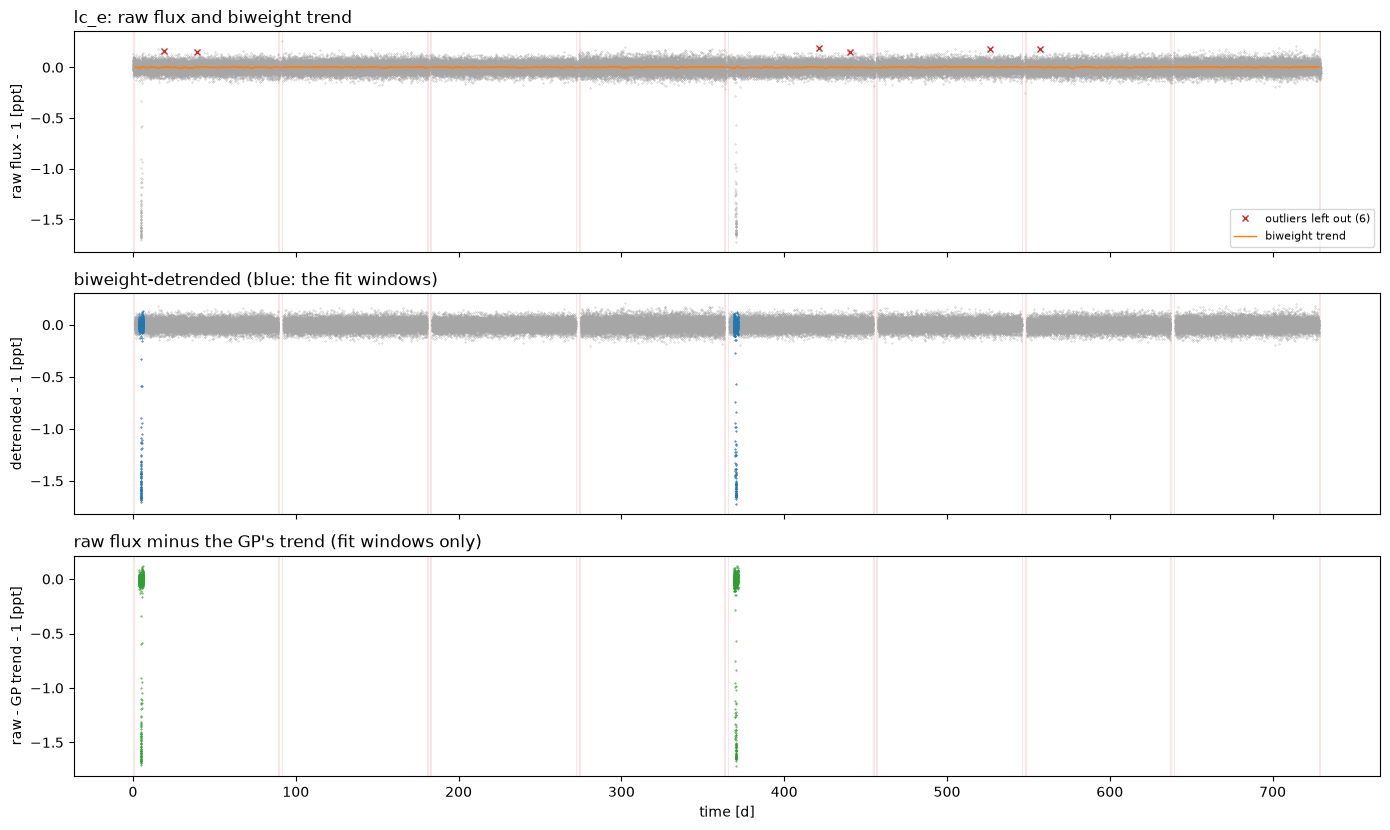

In [15]:
tr_gp = blind.gp_trends(s_gp, gp, gpw["time"], gpw["flux"], gpw["flux_err"])
blind.plot_lightcurve(t, f, T0, P, HALF, bw=bw, gp_trend=(gpw["time"], gpw["flux"], tr_gp["mu_moon"]), bad=outliers,
                      edges=edges,
                      title=f"lc_{NAME}: raw flux and biweight trend")
plt.show()

### 8.1b How well do the two detrenders follow the systematics?

The raw flux around the first transits, zoomed to the out-of-transit level (the transit itself runs off the bottom;
grey band), with the biweight trend (blue) and the GP's trend (red: its posterior mean predicted from the data outside
the transits, with its 1σ band). Below: the raw flux minus each trend in 1-h bins. Wherever the trend follows a
systematic, the residual is flat; wherever a trend follows a real signal next to the transit (a moon), that signal
disappears from the residual. In the fits the trend and the transit model are not separated this way: the biweight is
fixed before the fit, the GP is fitted together with the planet and moon.

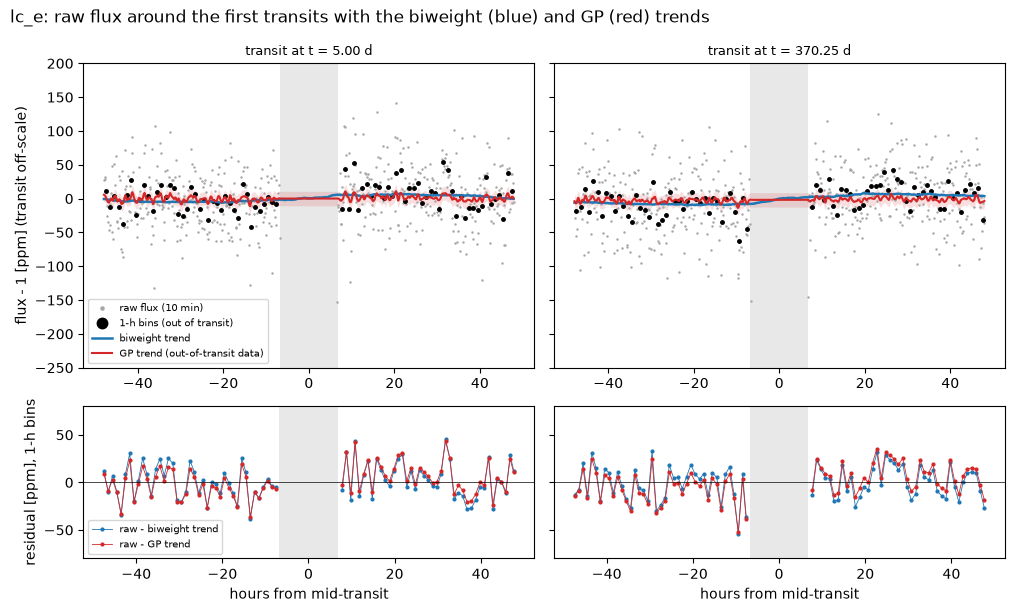

In [16]:
fig = blind.plot_detrending(t, f, bw, gp, sigma, T0, P, T14, n_transits=3, halfwidth=min(2.0, 0.45 * P), bad=bad,
                            title=f"lc_{NAME}: raw flux around the first transits with the biweight (blue) and GP (red) trends")
plt.show()

mean level in the day before the transits: -8.2 ppm; in the day after: +13.4 ppm (+- 2.6 ppm)


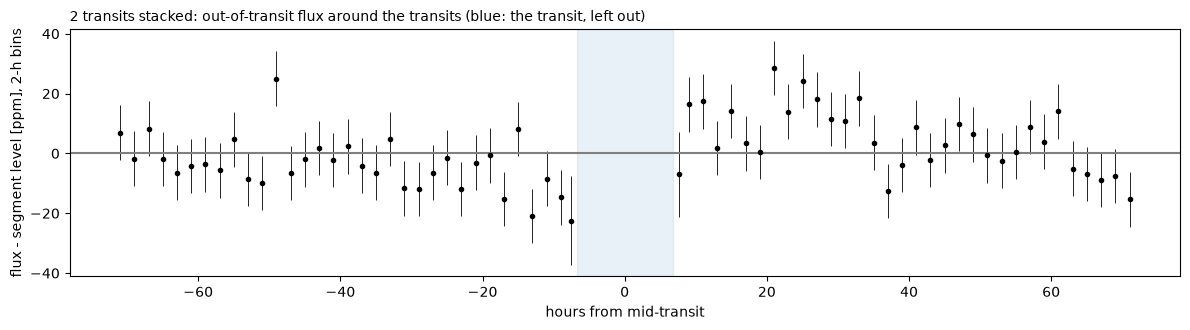

In [17]:
# all transits stacked: is there a systematic tied to the transits? (lc_a: its moon dip after the second transit is
# left out with skip=..., see texts)
fig = blind.plot_post_transit(t, f, sigma, T0, P, T14, [T0 + P * e for e in ft["epoch"]], bad=bad,
                              skip=SKIP_STACK if "SKIP_STACK" in globals() else None)
plt.show()

**The two detrenders agree.** Both trends are flat to ±10 ppm around both transits; the biweight steps up by ~10 ppm across
each transit, following the brightening below.

**Post-transit brightening (all six light curves).** The stack of all transits shows a systematic that no single
transit reveals: in the one to two days after each transit the flux is higher than the segment level, by ~10–20 ppm (two transits: noisy), and
it fades within ~40 hours; before the transits the level is normal. At random times away from the transits the same
comparison gives −0.6 ± 0.4 ppm. The effect appears in all six light curves, with about the same duration whatever the
planet's period, and is not proportional to the transit depth. It looks like an instrumental or processing memory
effect (a slow recovery after the star dims), not like anything a star, planet or moon does. Ask the data's author.

For the fits: the biweight follows it partly (the steps in its trend above); the GP with its 10-min time scale and one
constant level per window does not. Neither model can turn a brightening into a moon's dip, so it does not create
moons; it does leave residuals of ~10–20 ppm (two transits: noisy) after the transits.

### 8.2 The transits with the best planet-only and planet+moon models

As in the characterisation tutorial: one column per transit, the data (grey: 10-min, black: 1-h bins) with the
best-fit planet-only (blue) and planet+moon (red) models. Below: the data minus the planet of the planet+moon fit (its
planet component), with the moon's own transit in that fit (red; it can only dim the star). This is what the moon model
attributes to the moon: where the black points follow the red curve, the data contain the moon's dip.

In [18]:
jk = r_gp["jackknife"]
order = np.argsort(jk["dchi2_epochs"])[::-1]
show = sorted(np.array(jk["epochs"])[order[:6]])          # at most 6 transits: those where the moon matters most
tmids = [T0 + P * e for e in show]
PLOT_HALF = min(HALF, 2.5 * T14 + 0.25)     # half-width of the transit plots [d]

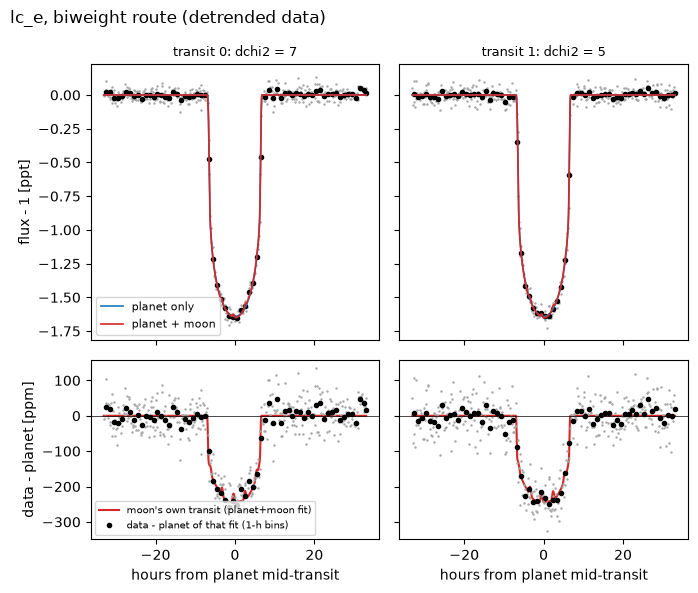

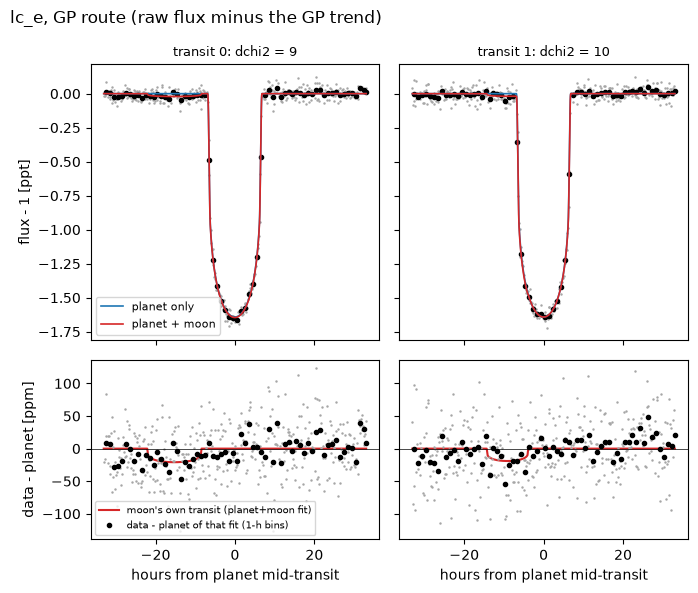

In [19]:
for lab, s, r in (("biweight", s_bw, r_bw), ("GP", s_gp, r_gp)):
    tg, gm, gpl, gpc = blind.model_on_grid(s, tmids, PLOT_HALF)
    jk = r["jackknife"]
    dch = dict(zip(jk["epochs"], jk["dchi2_epochs"]))
    labels = [f"transit {e}: dchi2 = {dch.get(e, np.nan):.0f}" for e in show]
    if lab == "biweight":
        tc, data, fm, fp = blind.best_models(s)
        fpc = blind.best_planet_component(s)
        blind.plot_transits(tc, data, fm, fp, tmids, labels, halfwidth=PLOT_HALF, model_time=tg, model_moon=gm,
                            model_planet=gpl, f_planet_comp=fpc, model_planet_comp=gpc,
                            title=f"lc_{NAME}, biweight route (detrended data)")
    else:
        blind.plot_transits(gpw["time"], gpw["flux"] - tr_gp["mu_moon"], tr_gp["f_moon"], tr_gp["f_planet"], tmids,
                            labels, halfwidth=PLOT_HALF, model_time=tg, model_moon=gm, model_planet=gpl,
                            f_planet_comp=tr_gp["f_planet_comp"], model_planet_comp=gpc,
                            title=f"lc_{NAME}, GP route (raw flux minus the GP trend)")
    plt.show()

**The two models coincide** (top). The best planet+moon fit hides its moon in the planet's transit: a moon on a tight orbit that crosses the star together with the planet at every transit (~240 ppm), while the planet is made slightly smaller. The data minus that planet (bottom) then look like a moon's dip, but the top panel shows the point: the planet-only model (blue) fits the same transits as well as the planet+moon model (red). A slightly smaller planet plus a co-transiting moon and a slightly larger planet alone give the same light curve; the moon adds parameters without explaining anything the planet cannot, so the Bayes factor prefers the planet alone (section 7).

### 8.3 Residuals of the best planet+moon model: spots, artefacts, a wrong transit shape?

If the planet+moon model describes the data, its residuals are noise. Synthetic star spots crossed by the planet would
show as bumps *inside* the transit, a wrong limb-darkening law or exposure time as a pattern at ingress and egress,
and instrumental dips as structure outside. χ²/N compares the residuals with the error bars (for the GP route: the
white-noise part, σ(t) × err_scale, after subtracting the GP trend).

biweight: residuals of the best planet+moon model (chi2/N: 1 = as expected from the error bars)
   transit time   chi2/N in transit   chi2/N outside   mean in-transit residual [ppm]
        5.000          0.60              0.85           +1.0 +- 5.3
      370.251          0.68              0.79           -2.9 +- 5.4
GP: residuals of the best planet+moon model (chi2/N: 1 = as expected from the error bars)
   transit time   chi2/N in transit   chi2/N outside   mean in-transit residual [ppm]
        5.000          0.72              0.87           +0.3 +- 4.9
      370.251          0.76              0.85           -0.8 +- 5.1


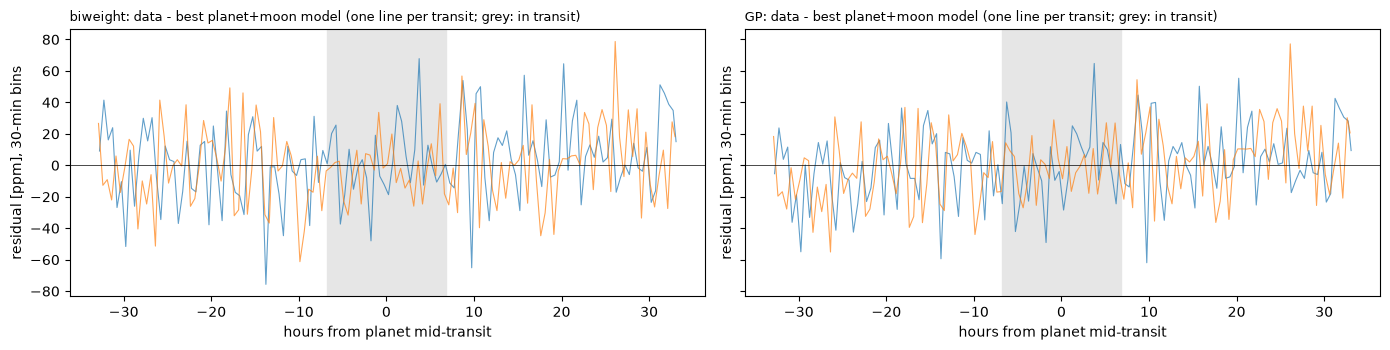

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(14, 3.6), sharey=True)
tc, data, fm, fp = blind.best_models(s_bw)
lc_err = np.interp(tc, bw["time"], bw["flux_err"])
res_rows_bw = blind.residual_check(tc, data - fm, lc_err, [T0 + P * e for e in ft["epoch"]], T14, PLOT_HALF,
                                   label="biweight", ax=axs[0])
res_rows_gp = blind.residual_check(gpw["time"], gpw["flux"] - tr_gp["mu_moon"] - tr_gp["f_moon"],
                                   gpw["flux_err"] * gp.err_scale, [T0 + P * e for e in ft["epoch"]], T14, PLOT_HALF,
                                   label="GP", ax=axs[1])
plt.tight_layout()
plt.show()

**The residuals are noise.** The mean in-transit residuals are +1 ± 5 and −3 ± 5 ppm (GP: 0 ± 5, −1 ± 5). χ²/N is
0.6–0.9, below 1 because the error bars include the red-noise factor β = 1.06 (they are meant for averages over hours,
where neighbouring points are correlated), and because the in-transit values rest on only ~80 points each.

### 8.4 Posteriors: the moon

Corner plot of the moon's parameters, both routes (blue: biweight, red: GP). r_moon in stellar radii, per_moon in
days, M_moon / M_planet, the inclination i_moon and orientation Ω_moon [deg] of the moon's orbit, and its phase
tau_moon at the first transit. Ω is folded to 0–180° (Ω and Ω + 180° give the same light curves at the transits).

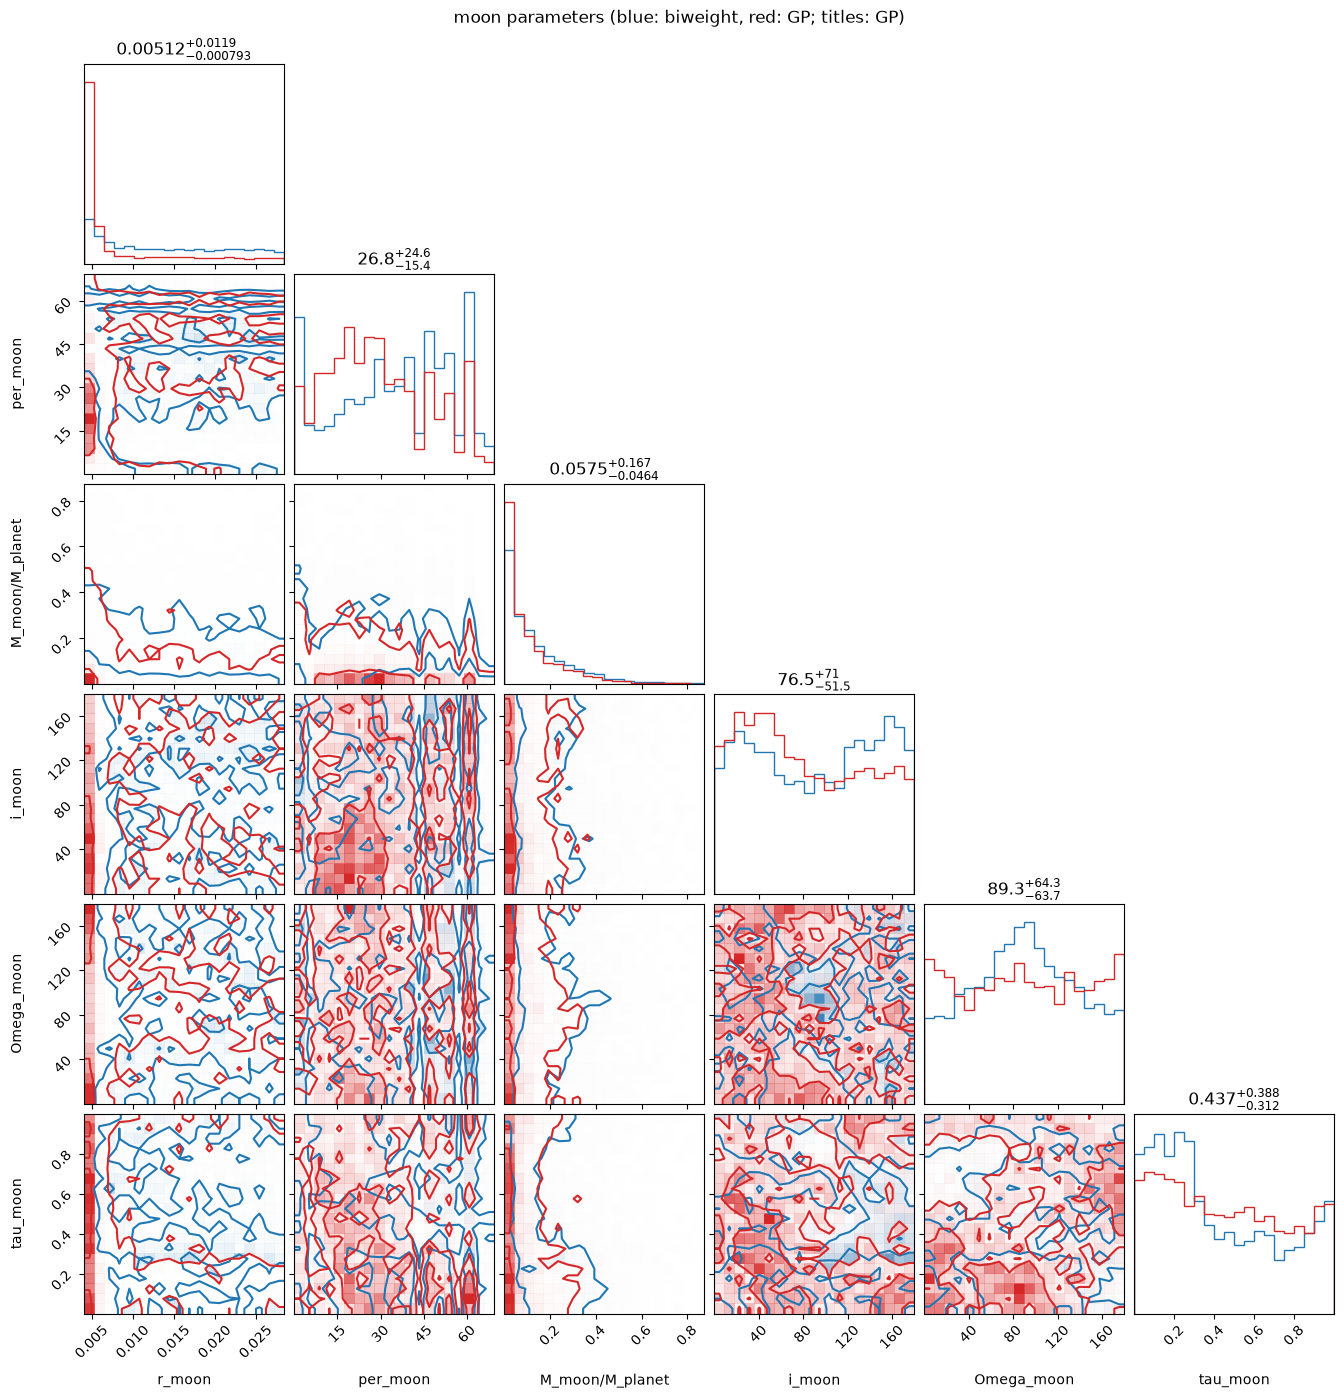

In [21]:
import corner
S_bw, S_gp = blind.samples_dict(r_bw), blind.samples_dict(r_gp)
keys = ["r_moon", "per_moon", "M_moon/M_planet", "i_moon", "Omega_moon", "tau_moon"]
hk = dict(density=True)
fig = corner.corner(np.column_stack([S_bw[k] for k in keys]), labels=keys, color="C0", hist_kwargs=dict(hk, color="C0"),
                    plot_datapoints=False, levels=(0.393, 0.865))
corner.corner(np.column_stack([S_gp[k] for k in keys]), fig=fig, color="C3", hist_kwargs=dict(hk, color="C3"),
              plot_datapoints=False, levels=(0.393, 0.865), show_titles=True, title_fmt=".3g")
fig.suptitle("moon parameters (blue: biweight, red: GP; titles: GP)", y=1.01)
plt.show()

**The moon posterior is broad.** Radius 0.005–0.024 stellar radii (68 %), with a GP-route peak at the smallest radii;
period, orientation and mass ratio are unconstrained. A 1 650-ppm planet with ~45 ppm noise per point leaves room for
moons whose dips (up to ~200 ppm for 0.014 R★, spread over hours) are hidden in front of or behind the planet at two
transits.

### 8.5 Posteriors: planet and star in the planet+moon model

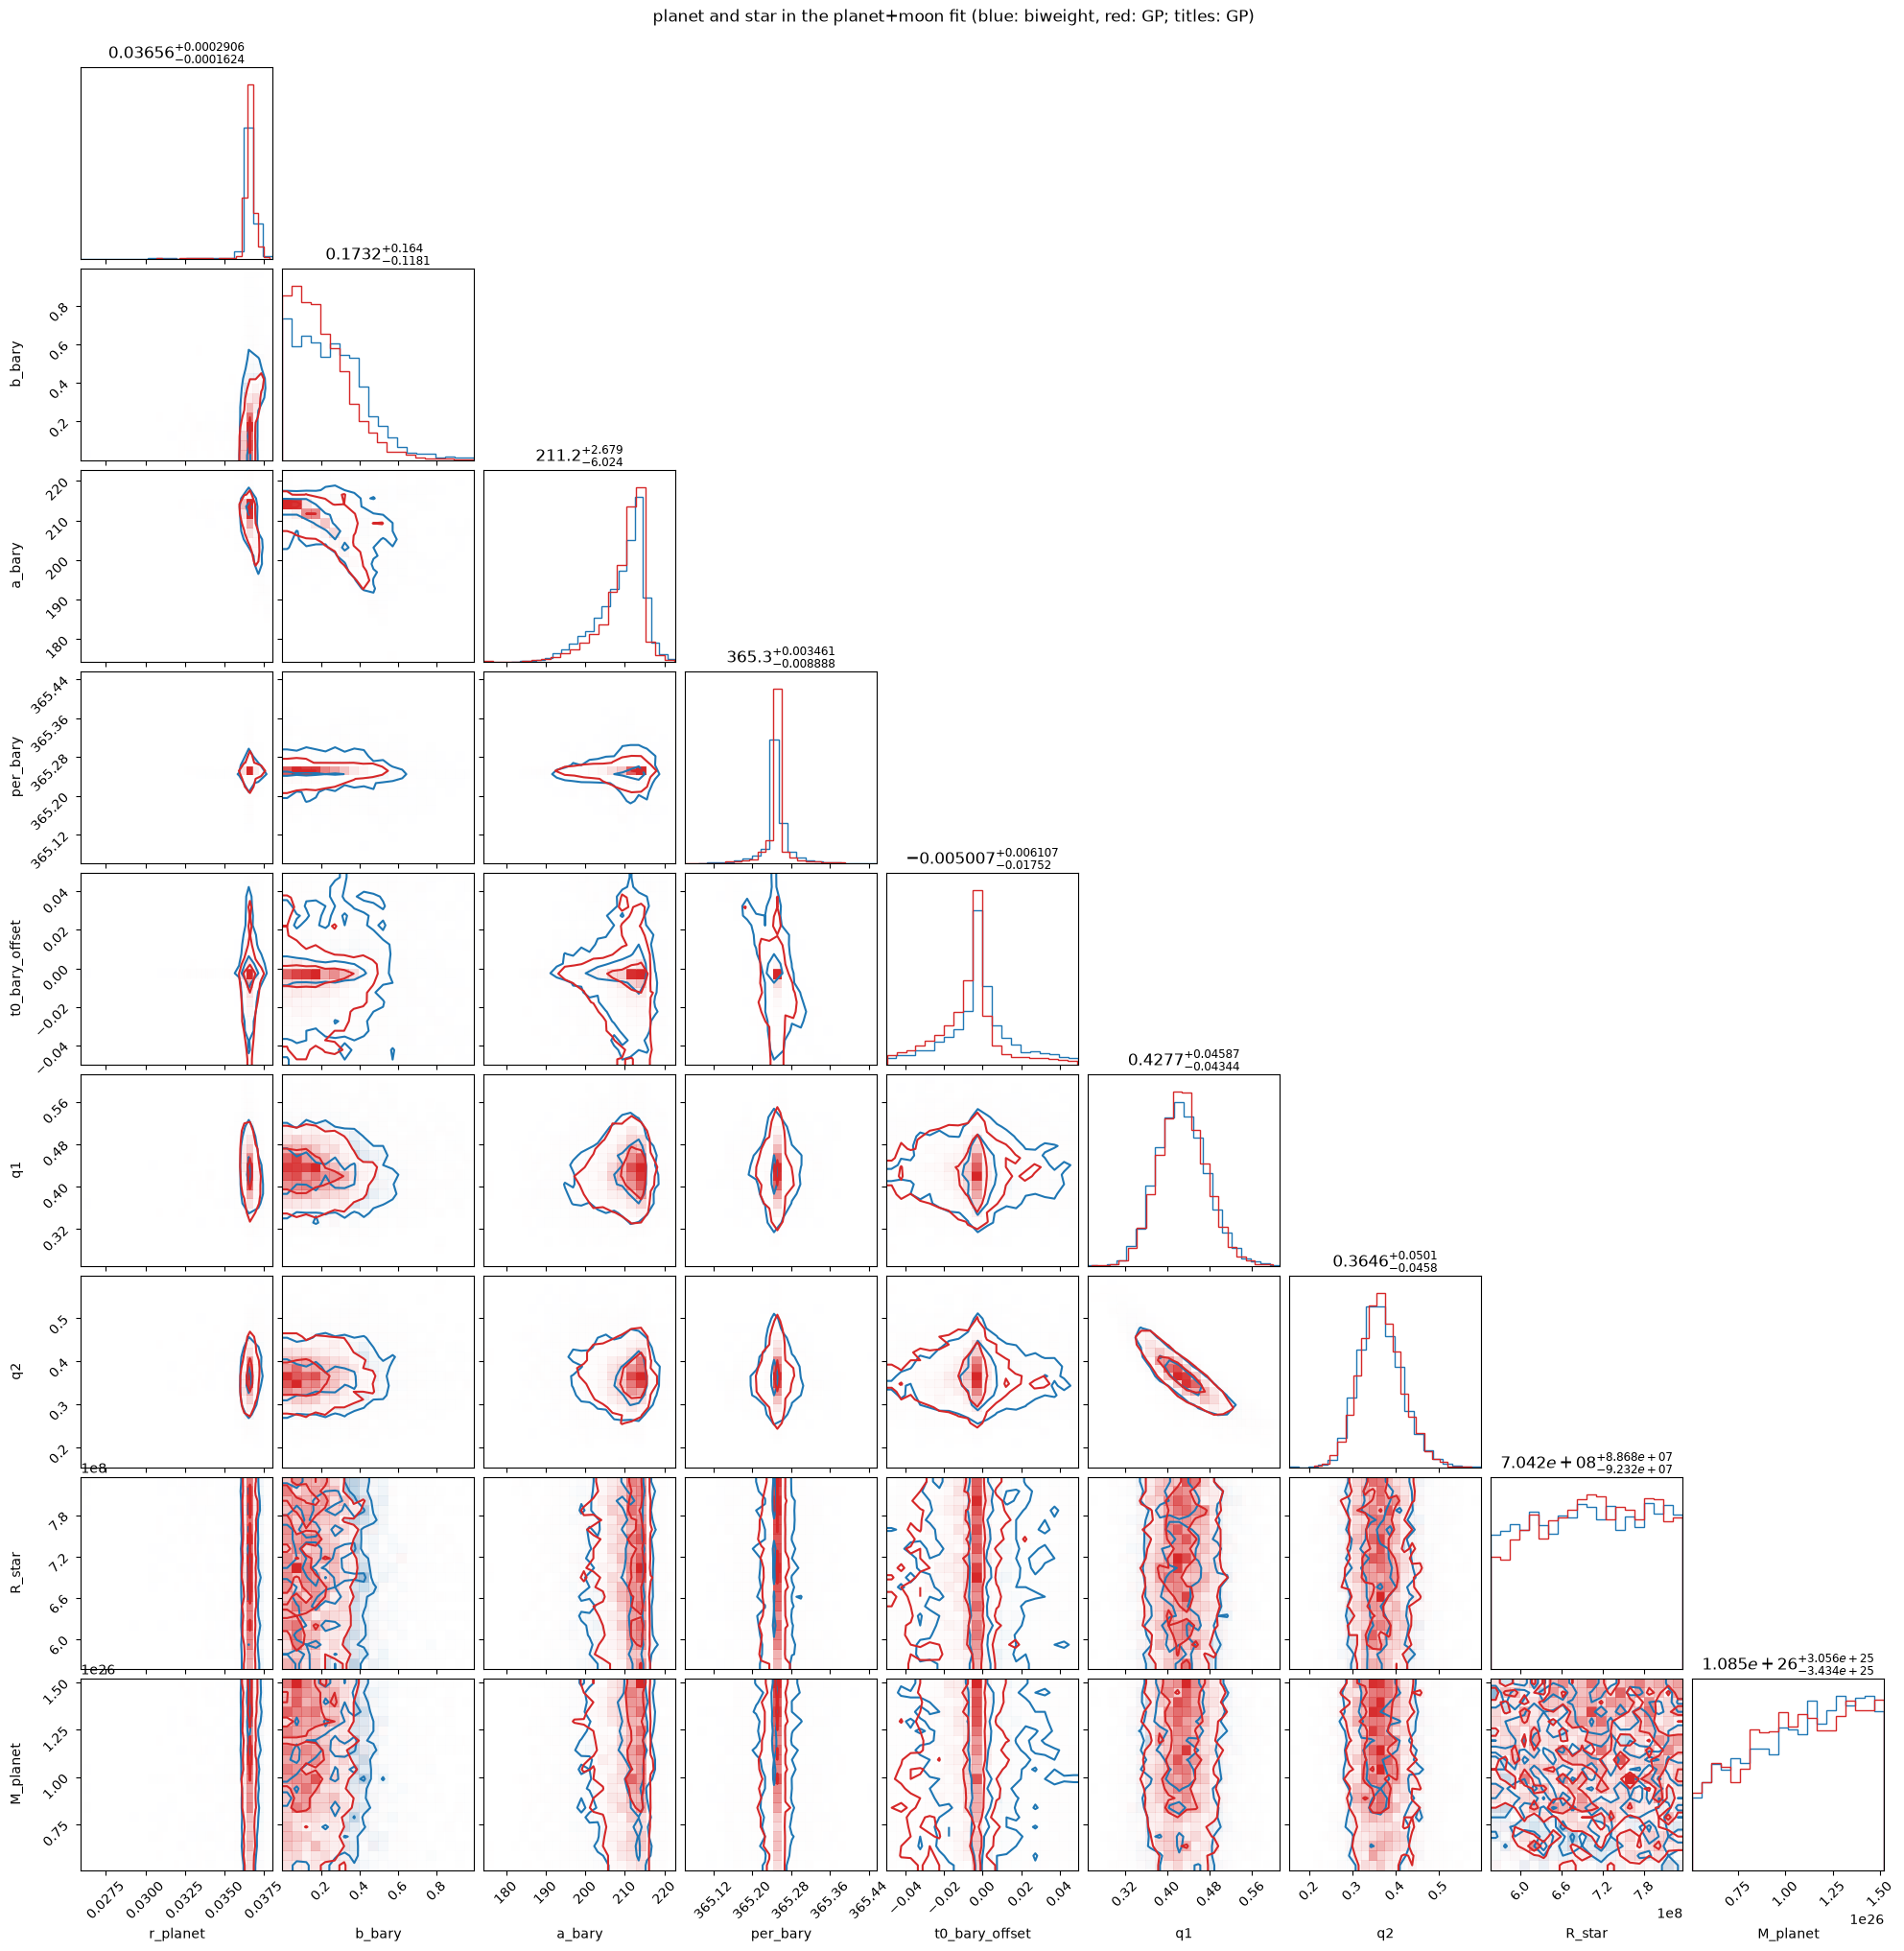

In [22]:
keys = ["r_planet", "b_bary", "a_bary", "per_bary", "t0_bary_offset", "q1", "q2", "R_star", "M_planet"]
fig = corner.corner(np.column_stack([S_bw[k] for k in keys]), labels=keys, color="C0", hist_kwargs=dict(hk, color="C0"),
                    plot_datapoints=False, levels=(0.393, 0.865))
corner.corner(np.column_stack([S_gp[k] for k in keys]), fig=fig, color="C3", hist_kwargs=dict(hk, color="C3"),
              plot_datapoints=False, levels=(0.393, 0.865), show_titles=True, title_fmt=".4g")
fig.suptitle("planet and star in the planet+moon fit (blue: biweight, red: GP; titles: GP)", y=1.01)
plt.show()

**Planet and star.** r_planet = 0.0366 ± 0.0003 stellar radii (4.0 R_earth for a solar radius), b ≈ 0.2. R_star and
M_planet are set by their priors.

### 8.6 Posteriors: the GP's trend parameters

The fit holds the GP's hyperparameters fixed at their `GP.fit` values. How well do the data constrain them? A short
Metropolis chain over (amp, tau, err_scale) on the residuals of the best planet+moon model in the fit windows
(log-uniform priors over `GP.fit`'s bounds) shows their posterior. `gp_profile` (section 6) refits them for each model.

Metropolis acceptance 0.20; GP.fit values: amp 10.5 ppm, tau 10.0 min, err_scale 0.989
amp 207.6 ppm (68 %: 28.5 ... 1154.5); tau median 36110 min; err_scale 0.944


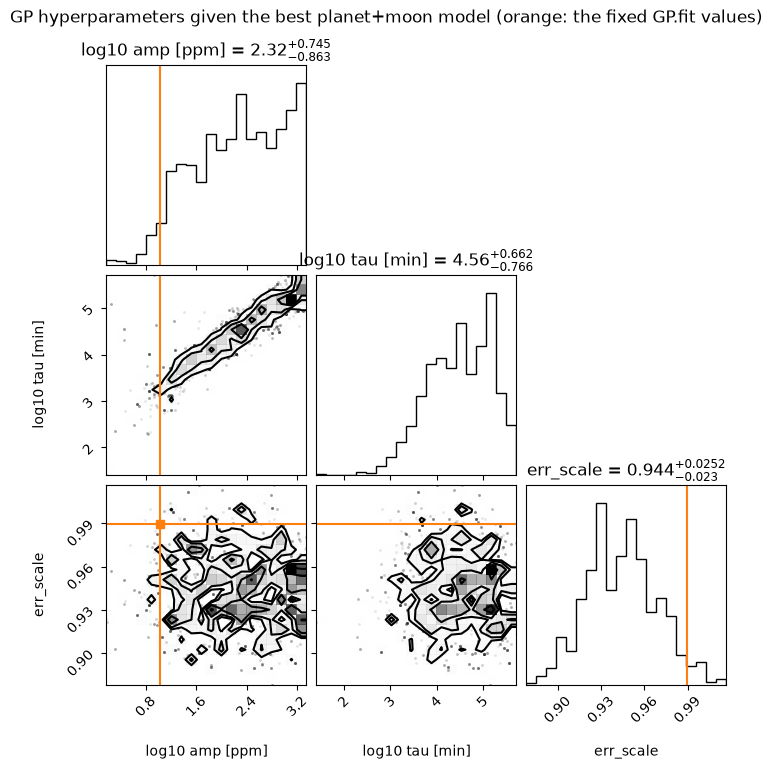

gp_profile: {'dlogz': -3.6472366380318704, 'dlogzerr': 0.09168900977890851, 'dlogz_fixed': -2.0635291546938106, 'ess_moon': 10629.46047946443, 'seconds': 27.228512409958057}


In [23]:
resid1 = gpw["flux"] - tr_gp["f_moon"] + 1.0
post = blind.gp_posterior(gp, gpw["time"], resid1, gpw["flux_err"], n_steps=6000, n_burn=1500)
print(f"Metropolis acceptance {post['acceptance']:.2f}; GP.fit values: amp {1e6 * gp.amp:.1f} ppm, "
      f"tau {1440 * gp.tau:.1f} min, err_scale {gp.err_scale:.3f}")
# log axes: where the data constrain the GP weakly, the chain spreads over orders of magnitude
X = np.column_stack([np.log10(1e6 * post["amp"]), np.log10(1440 * post["tau"]), post["err_scale"]])
fig = corner.corner(X, labels=["log10 amp [ppm]", "log10 tau [min]", "err_scale"], show_titles=True,
                    title_fmt=".3g", truths=[np.log10(1e6 * gp.amp), np.log10(1440 * gp.tau), gp.err_scale],
                    truth_color="C1")
lo, med, hi = np.percentile(post["amp"], [16, 50, 84]) * 1e6
print(f"amp {med:.1f} ppm (68 %: {lo:.1f} ... {hi:.1f}); tau median {1440 * np.median(post['tau']):.0f} min; "
      f"err_scale {np.median(post['err_scale']):.3f}")
fig.suptitle("GP hyperparameters given the best planet+moon model (orange: the fixed GP.fit values)", y=1.02)
plt.show()
if r_gp.get("gp_profile"):
    print("gp_profile:", {k: v for k, v in r_gp["gp_profile"].items() if not hasattr(v, "__len__") or isinstance(v, str)})

**The GP's hyperparameters in the windows** agree with the near-white noise found outside them.

## 9. The physics of the planet+moon solution

From the posterior samples (GP route): the star's mass follows from a_bary, per_bary and R_star (Kepler's third law),
the moon's orbit from its period and the masses. Radii and masses in Earth and Jupiter units, densities, the moon's
orbit in planet radii and as a fraction of the planet's Hill radius, the Roche limit, and the planet's timing wobble.

In [24]:
Q = blind.physics(S_gp)
blind.print_physics(Q)

  M_star [M_sun]                                                     0.9627   (68 %: 0.6333 ... 1.372)
  R_star [R_sun]                                                      1.011   (68 %: 0.8781 ... 1.139)
  rho_star [g/cm^3]                                                   1.336   (68 %: 1.224 ... 1.388)
  a_bary [AU]                                                        0.9874   (68 %: 0.8587 ... 1.111)
  R_planet [R_jup]                                                     0.36   (68 %: 0.313 ... 0.4059)
  R_planet [R_earth]                                                  4.039   (68 %: 3.512 ... 4.554)
  M_planet [M_jup]                                                  0.05715   (68 %: 0.0389 ... 0.07331)
  rho_planet [g/cm^3]                                                 1.486   (68 %: 0.95 ... 2.36)
  R_moon [R_earth]                                                   0.5785   (68 %: 0.4634 ... 1.893)
  M_moon [M_earth]                                                    1.031 

**No moon, so no moon physics.** The table shows the prior-dominated moon posterior for completeness only. The planet:
0.0366 stellar radii = 4.0 R_earth, a Neptune on a one-year orbit around a star of the Sun's mean density
(1.33 ± 0.08 g cm⁻³).

## 10. Further checks: audit and injection-retrieval tests

Four of the six blind light curves gave no moon, so we searched for errors in our own analysis, in two ways:

- an **audit**: cheap checks of each step and assumption (priors, fit windows, noise, detrending, transit model);
- **injection-retrieval tests**: synthetic moons are inserted into the real light curve, the light curve is analysed
  again exactly as in this notebook, and we count how many moons are found.

**What the audit found, for all six light curves:**

- **Priors:** no moon parameter piles up at the upper edge of its prior (radius, period, mass) in any fit, so the data
  do not ask for larger, wider or heavier moons than allowed. Pile-ups at lower edges are expected: the impact
  parameter at 0 (central transits) and, in the no-moon fits, the shortest moon periods (the "hiding places" inside
  the Roche limit).
- **Fit windows:** fully covered by data in every light curve, and no significant dip just outside them (searched out
  to the Hill radius of a 1.5 Jupiter-mass planet).
- **Noise:** the noise σ(t) must be estimated with the transits masked; otherwise the steep ingress and egress
  inflate it by 15–23 % near deep transits (our first round of fits had this bias and was redone). With the mask, the
  errors are calibrated (χ²/N = 0.9–1.04 near the transits).
- **Transit model:** the stacked planet-only residuals show no pattern at ingress, egress or the transit bottom;
  quadratic limb darkening and 10-minute exposures (5 sub-exposures) are adequate at this precision.
- **Detrending:** the biweight keeps deep moon dips (300 ppm: 88–100 % of the dip), but removes 25–30 % of a
  shallow (80 ppm) dip that lasts as long as the transit, i.e. 40–50 % of its Δχ². The GP with its fitted 10-minute
  time scale keeps 62–86 % of a dip's evidence; slower GPs (as in the conservative Bayes factor) keep only 6–13 %,
  which is why the conservative value is a lower bound.
- **`detect` setting:** at its default `recall=0.95`, `detect` sometimes misses the moon model's mode (lc_b). With
  `recall=0.999` (a few seconds more) repeated runs agree; we used it for all injection tests.
- **Two signals no model includes:** a **post-transit brightening** (+5 to +20 ppm for ~40 hours after every transit,
  in all six light curves; it can cancel part of a trailing moon's dip), and a **slow deepening of the transits**
  (most light curves by ~0.2 % per year). A transit that changes with time favours the planet+moon model, because the
  planet-only model has one fixed transit shape.

**A null model for a changing transit.** Pandora's planet-only model has one transit depth for all transits. As a
check, we fitted the biweight data of each light curve (maximum likelihood) with the best planet-only transit whose
depth changes linearly with time (one extra parameter), and with a free depth for each transit, and compared them with
the planet+moon model (nine extra parameters). Δ BIC = Δχ² − (extra parameters) × ln N; positive favours the model
over the planet with a fixed transit:

| light curve | transits | depth change per year | Δχ² linear depth (1) | Δχ² free depth per transit | Δχ² planet+moon (9) | Δ BIC linear depth | Δ BIC planet+moon |
|---|---|---|---|---|---|---|---|
| lc_a | 2 | +0.56 % | 26 | 26 | 1696 | +19 | +1630 |
| lc_b | 8 | +0.46 % | 168 | 198 | 193 | +160 | +124 |
| lc_c | 2 | +0.35 % | 13 | 13 | 25 | +6 | −42 |
| lc_d | 8 | +0.20 % | 12 | 24 | 27 | +4 | −42 |
| lc_e | 2 | +0.28 % | 0.3 | 0.3 | 12 | −6 | −49 |
| lc_f | 32 | +0.43 % | 6 | 51 | 34 | −2 | −37 |

Only lc_a's moon beats a changing transit by far; in lc_c and lc_d a slow deepening explains half of the moon model's
small improvement. (For lc_b the planet+moon fit did not converge; its section 10 shows that timing variations add to
the picture.) **Transit timing:** fitted transit by transit with the planet's own shape, the mid-times of lc_d
(8 transits, ±0.12 min) and lc_f (32 transits, ±0.4 min) scatter close to their errors (χ² 18 for 7 degrees of
freedom, a mild excess of ±0.2 min, and 36 for 31); only lc_b shows strong timing variations (χ² 142 for 7, ±0.48 min).
With two transits (lc_a, lc_c, lc_e) a timing variation cannot be told apart from the period.

**How the injection tests work.**

1. Take this light curve's best planet-only model (the planet as found above).
2. Multiply a planet+moon model in: Pandora's model with the moon's radius and period from a grid, the moon in the
   planet's orbital plane at a random orbital phase, an Earth-like density (5.5 g/cm³), and the planet mass of our
   prior's centre. The data keep their real noise and systematics.
3. Clean and analyse it exactly as in this notebook: biweight detrending redone on the injected flux; the GP with
   this light curve's hyperparameters; `pandora.detect` (`recall=0.999`) on both routes.
4. Count a moon as found if Δln Z > 8 (strong evidence). Each cell of the map holds 15–20 injections; the light curve
   without an injected moon is analysed the same way, as a control.

Limits of the maps: they use `detect` (seconds per run) rather than full fits (minutes to hours each; how much more
sensitive the full fits are was not calibrated here); there is one noise realisation (the real light curve); moons outside the prior (wider
orbits, a heavier planet) are not in the maps (the lc_e and lc_f notebooks test a heavier planet separately).

**Which moons would we have found in lc_e?** 1120 injections (moon radius 0.3–2.8 R_earth, period 0.5–60 days,
around a 17 M_earth planet), and 20 controls without a moon (largest Δln Z +2.0, none above 8):

![lc_e sensitivity map](figures/sensitivity_e.png)

- **Half of the moons are found at ~0.75 R_earth** (both routes), **90 % at ~1.0 R_earth** (a dip of 84 ppm). Around
  a Neptune-size planet (dip 1350 ppm) an Earth-size moon is a large moon: 1/4 of the planet's radius.
- **Short orbits are harder:** at periods of 2 days or less a 0.7 R_earth moon is (almost) never found, a 1 R_earth moon in
  70–95 % of the cases. On wide orbits (32–60 days) the GP route finds half of the 0.5 R_earth moons.
- The GP route is somewhat more sensitive for the smallest moons on wide orbits (0.5 R_earth: 18 % against 3 %),
  consistent with the biweight's loss of shallow, long dips (audit above).
- **Tilted orbits:** for 1 R_earth moons on randomly oriented orbits the detection rate drops from 94–96 % (in the
  planet's orbital plane) to 65 % (biweight) and 66 % (GP): short orbits (0.5–2 days: 10–40 %) lose most, orbits of
  8–32 days are still found every time.
- **Trailing moons are partly hidden by the post-transit brightening:** at the same radius and period, moons whose dips
  fall mostly after the transit are found in 24–28 % of the cases, those mostly before it in 71–79 % (±11 %). lc_e
  keeps +9 ± 4 ppm of the brightening after the transit even after the biweight (a threshold moon's dip is ~40 ppm).
  Trailing moons need ~0.1 R_earth more to be found equally often; from ~1 R_earth on it makes no difference.

![leading vs trailing moons](figures/leadtrail.png)

**For the verdict:** an Earth-density moon of Earth's size or larger in the planet's orbital plane would very likely
have been found; on a tilted orbit shorter than a few days, or trailing the planet near the detection limit, it could
have been missed.

**Audit items specific to lc_e.**

- **The planet-mass assumption.** We used Neptune's mass (17 M_earth); it sets how far the moon can be from the planet
  (at most 0.82 days of transit time), and so the fit windows (±1.38 days). If the planet were as heavy as Jupiter,
  its moons could be further out. We tested this with 96 injections of moons around a Jupiter-mass planet
  (0.7–1.4 R_earth, periods 8–60 days):
  - analysed as in this notebook (Neptune-mass prior and windows), moons on 8–16-day orbits are all found, but on
    32–60-day orbits only 12–88 % (1.4 R_earth at 60 days: 25–38 %): their dips fall outside the windows;
  - analysed with a Jupiter-mass prior and its wider windows (±2.73 days), 88–100 % are found;
  - **`detect` on the real lc_e with the Jupiter-mass prior** gives Δln Z = −3.0 to +0.4 (8 runs, both routes): no
    moon there either. The Neptune-mass assumption did not hide a moon in this light curve.
- **No transit deepening**: −0.4 ± 0.7 % per year (only two transits).

## 11. Assessment, and what we learned

### Assessment

**lc_e has no detectable moon.** The planet-only model is preferred in every full fit (conservative Δln Z = −3.65,
B ≈ 38, "very strong" on Jeffreys' scale); all fits passed their checks; the jackknife fails; the two transits are
identical in duration (to 0.2 min) and shape.

For a Neptune-size planet the moons the prior allows are small (≤ 3.1 R_earth, dips ≤ 800 ppm). With two transits
and ~45 ppm noise per 10-min point, moons that were behind or in front of the planet at both transits, or Earth-size
and smaller moons with dips of tens of ppm, would not be seen.

### What we learned

1. **Give the planet's mass** for small planets: the Jupiter-mass default would have widened the moon prior (and the
   windows) to orbits a Neptune cannot hold; we used 17 M_earth. (Proposed fix 6 does this automatically.)
2. **Quick and clean**: both full fits took 2 minutes and passed every check.
3. **`detect`'s two values (−4.8 and −0.3)** show its scatter; both are far from its threshold of +3, so it answered
   the question correctly.

## Reproducibility

The run times and versions of this notebook's fits:

In [25]:
import platform
for lab, r in (("biweight", rec_bw), ("GP", rec_gp)):
    print(f"{lab:9s}: planet+moon fit {r['wall'] / 60:6.1f} min, {r['ncall'] / 1e9:.2f} G likelihood calls, "
          f"n_live {r['nlive']}, nsteps {r['nsteps']}, status {r['status']} ({r['date']})")
print("detect wall time: biweight %.1f s, GP %.1f s" % (det_bw["wall"], det_gp["wall"]))
print(platform.platform(), "| python", platform.python_version())
try:
    import numba.cuda
    print("GPU:", str(numba.cuda.get_current_device().name) if numba.cuda.is_available() else "none")
except Exception as e:
    print("GPU: not available", e)

biweight : planet+moon fit    2.6 min, 1.16 G likelihood calls, n_live 500, nsteps 64, status passed (2026-11-21T11:43:04)
GP       : planet+moon fit    2.4 min, 0.63 G likelihood calls, n_live 500, nsteps 64, status passed (2026-11-21T10:55:22)
detect wall time: biweight 17.9 s, GP 15.7 s
Linux-6.1.0-54-amd64-x86_64-with-glibc2.36 | python 3.12.2


GPU: NVIDIA GeForce RTX 5060
